# Чекпоинт №2 — EDA дорожных сцен и неизвестных объектов

**Тема:** обнаружение неизвестных объектов в дорожных сценах.


In [43]:
# Общие импорты для EDA
from pathlib import Path
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from scipy import ndimage


## 1. Цель и постановка

EDA описывает свойства дорожных изображений и разметки, важные для последующего исследования MSP и Energy по выходам модели семантической сегментации. Анализ сосредоточен на пригодности данных для исследования неизвестных объектов, в том числе малых и удалённых, и на ограничениях имеющейся разметки.

Неизвестность класса и препятствие на дороге — разные задачи. RoadAnomaly21 размечает неизвестные объекты в сцене; RoadObstacle21 ищет объекты в области дороги, в том числе известные. В этом проекте основной набор для анализа неизвестных объектов — RoadAnomaly21; Lost & Found относится к дополнительной проверке малых дорожных опасностей.

## 2. Выбор данных и протокол

| Набор | Роль | Что даёт | Ограничение |
|---|---|---|---|
| Cityscapes fine | Обучение/валидация модели известных классов | Детальная семантическая разметка; открытые части: 2 975 train и 500 val | Не содержит целевой коллекции неизвестных объектов и сам по себе не обучает OOD-детектор. |
| RoadAnomaly21 | Основная оценка неизвестных объектов | 100 benchmark test images; дополнительно опубликованы 10 размеченных изображений. Аномалии встречаются в разных местах сцены и сильно различаются размером. | Пороговые значения benchmark test в этом локальном EDA не подбираются; здесь проанализированы 10 опубликованных дополнительных изображений. |
| Fishyscapes Lost & Found | Дополнительный набор малых дорожных опасностей | Публичная validation-часть ориентирована на небольшие объекты на дороге | Отдельный набор со своим протоколом; в текущем EDA не анализируется. |

Постановка проекта рассматривает готовый сегментатор, обученный на Cityscapes, и оценки MSP/Energy по его логитам. В этом варианте RoadAnomaly21 служит для анализа и оценки неизвестных объектов, а не для обучения scoring-функции.

Источники: [Cityscapes overview](https://www.cityscapes-dataset.com/dataset-overview/), [описание разбиения Cityscapes](https://www.cityscapes-dataset.com/wordpress/wp-content/data/cordts2016cityscapes.pdf), [SegmentMeIfYouCan datasets](https://segmentmeifyoucan.com/datasets), [Fishyscapes dataset](https://fishyscapes.com/dataset). Дата обращения: 2026-11-09.

In [44]:
# Сводка из официальных описаний (не статистика локально загруженных файлов)

source_summary = pd.DataFrame([
    {"dataset":"Cityscapes fine", "role":"Известные классы: обучение/валидация сегментатора", "public_count":3475, "count_note":"2 975 train + 500 val с открытой разметкой", "annotation":"Семантическая разметка; benchmark использует 19 классов"},
    {"dataset":"RoadAnomaly21", "role":"Основная оценка OOD-сегментации", "public_count":10, "count_note":"10 дополнительно опубликованных размеченных изображений; отдельно 100 test images", "annotation":"anomaly / not anomaly / void"},
    {"dataset":"Fishyscapes Lost & Found", "role":"Дополнительная проверка малых дорожных опасностей", "public_count":None, "count_note":"Публичная validation-часть; число здесь не фиксируем", "annotation":"OOD-разметка; соблюдать протокол Fishyscapes"},
])
display(source_summary)


,dataset,role,public_count,count_note,annotation
0,Cityscapes fine,Известные классы: обучение/валидация сегментатора,3475.0,2 975 train + 500 val с открытой разметкой,Семантическая разметка; benchmark использует 1...
1,RoadAnomaly21,Основная оценка OOD-сегментации,10.0,10 дополнительно опубликованных размеченных из...,anomaly / not anomaly / void
2,Fishyscapes Lost & Found,Дополнительная проверка малых дорожных опасностей,NaN,Публичная validation-часть; число здесь не фик...,OOD-разметка; соблюдать протокол Fishyscapes


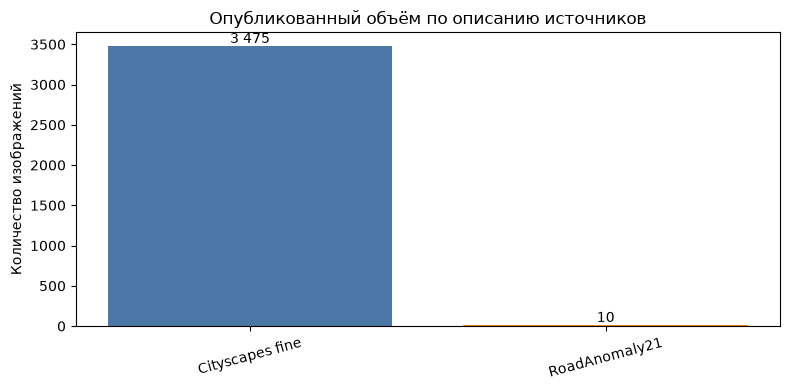

In [45]:
# Объёмы относятся к разным ролям и сплитам: график не сравнивает качество или сложность.
plot_df = source_summary.dropna(subset=["public_count"])
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(plot_df["dataset"], plot_df["public_count"], color=["#4C78A8", "#F58518"])
ax.set_ylabel("Количество изображений")
ax.set_title("Опубликованный объём по описанию источников")
ax.tick_params(axis="x", rotation=15)
for i, value in enumerate(plot_df["public_count"]): ax.text(i, value, f"{int(value):,}".replace(",", " "), ha="center", va="bottom")
plt.tight_layout(); plt.show()


### Предварительные выводы по документации

1. Cityscapes содержит разметку известных классов, а RoadAnomaly21 предназначен для оценки неизвестных объектов. Эти наборы выполняют разные роли в проекте.
2. Для RoadAnomaly21 опубликованы 10 дополнительных размеченных изображений; это небольшой набор для локальной проверки совместимости данных и анализа, а не репрезентативная обучающая выборка.
3. Официальное описание указывает широкий диапазон размера аномалий — примерно 0,5–40% изображения.
4. Маски содержат void-пиксели, которые не относятся ни к anomaly, ни к not-anomaly и исключаются из pixel-level расчётов.
5. Аномалии RoadAnomaly21 могут располагаться в разных частях сцены, а не только на проезжей части.

Эти выводы основаны на документации наборов; ниже они дополнены статистиками локальных изображений и масок.

## 4. Сопоставление пар и разрешения



In [46]:


IMAGE_DIR = Path("data/dataset_AnomalyTrack/images")
MASK_DIR = Path("data/dataset_AnomalyTrack/labels_masks")

def normalized_stem(path):
    return re.sub(r"_labels_semantic$", "", path.stem.lower())

image_files = sorted(IMAGE_DIR.glob("validation*.jpg"))
mask_files = sorted(MASK_DIR.glob("validation*_labels_semantic.png"))

images_by_stem = {normalized_stem(path): path for path in image_files}
masks_by_stem = {normalized_stem(path): path for path in mask_files}

common_stems = sorted(images_by_stem.keys() & masks_by_stem.keys())
pairs = [(images_by_stem[stem], masks_by_stem[stem]) for stem in common_stems]

print(
    f"Сопоставлено пар: {len(pairs)}; "
    f"без маски: {len(images_by_stem.keys() - masks_by_stem.keys())}; "
    f"без изображения: {len(masks_by_stem.keys() - images_by_stem.keys())}"
)

rows = []

for image_path, mask_path in pairs:
    with Image.open(image_path) as image:
        width, height, image_mode = image.width, image.height, image.mode

    with Image.open(mask_path) as mask:
        mask_width, mask_height, mask_mode = mask.width, mask.height, mask.mode

    rows.append({
        "image": image_path.name,
        "mask": mask_path.name,
        "width": width,
        "height": height,
        "image_mode": image_mode,
        "mask_mode": mask_mode,
        "mask_size_matches": (width, height) == (mask_width, mask_height),
    })

columns = [
    "image", "mask", "width", "height",
    "image_mode", "mask_mode", "mask_size_matches"
]
pairs_df = pd.DataFrame(rows, columns=columns)

display(pairs_df.head(10))
display(
    pairs_df.groupby(["width", "height"])
    .size()
    .rename("count")
    .reset_index()
)

matching_sizes = int(pairs_df["mask_size_matches"].sum())
print(f"Совпадают размеры маски и изображения: {matching_sizes} / {len(pairs_df)}")


Сопоставлено пар: 10; без маски: 0; без изображения: 0


,image,mask,width,height,image_mode,mask_mode,mask_size_matches
0,validation0000.jpg,validation0000_labels_semantic.png,1280,720,RGB,L,True
1,validation0001.jpg,validation0001_labels_semantic.png,1280,720,RGB,L,True
2,validation0002.jpg,validation0002_labels_semantic.png,1280,720,RGB,L,True
3,validation0003.jpg,validation0003_labels_semantic.png,1280,720,RGB,L,True
4,validation0004.jpg,validation0004_labels_semantic.png,1280,720,RGB,L,True
5,validation0005.jpg,validation0005_labels_semantic.png,1280,720,RGB,L,True
6,validation0006.jpg,validation0006_labels_semantic.png,1280,720,RGB,L,True
7,validation0007.jpg,validation0007_labels_semantic.png,1280,720,RGB,L,True
8,validation0008.jpg,validation0008_labels_semantic.png,1280,720,RGB,L,True
9,validation0009.jpg,validation0009_labels_semantic.png,1280,720,RGB,L,True


,width,height,count
0,1280,720,10


Совпадают размеры маски и изображения: 10 / 10


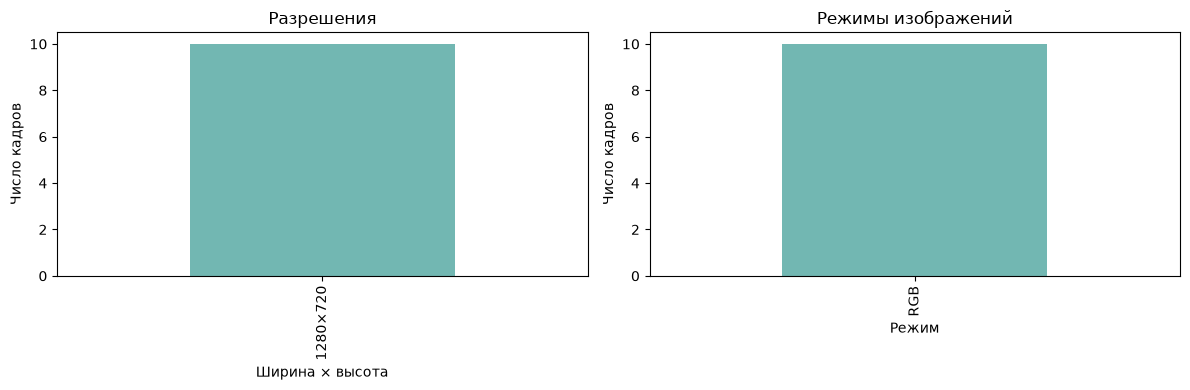

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

resolution_counts = (
    pairs_df["width"].astype(str)
    + "×"
    + pairs_df["height"].astype(str)
).value_counts()

resolution_counts.plot(
    kind="bar",
    ax=axes[0],
    color="#72B7B2"
)
axes[0].set_title("Разрешения")
axes[0].set_xlabel("Ширина × высота")
axes[0].set_ylabel("Число кадров")

pairs_df["image_mode"].value_counts().plot(
    kind="bar",
    ax=axes[1],
    color="#72B7B2"
)
axes[1].set_title("Режимы изображений")
axes[1].set_xlabel("Режим")
axes[1].set_ylabel("Число кадров")

plt.tight_layout()
plt.show()


## 5. Формат маски и распределение пикселей

Сначала изучаем реальные значения. Не предполагаем заранее, каким числом/цветом закодированы anomaly, not-anomaly и void. Это позволяет избежать неправильного подсчёта.


In [48]:

shape_counts = {}
pixel_counts = {}

for _, mask_path in pairs:
    with Image.open(mask_path) as mask:
        arr = np.array(mask)

    shape = arr.shape
    shape_counts[shape] = shape_counts.get(shape, 0) + 1

    values, counts = np.unique(arr, return_counts=True)
    for value, count in zip(values, counts):
        value = int(value)
        pixel_counts[value] = pixel_counts.get(value, 0) + int(count)

print("Формы масок:", shape_counts)

palette_df = pd.DataFrame([
    {"raw_value": value, "pixel_count": count}
    for value, count in sorted(
        pixel_counts.items(),
        key=lambda item: item[1],
        reverse=True
    )
])

palette_df["pixel_share"] = (
    palette_df["pixel_count"] / palette_df["pixel_count"].sum()
)

display(palette_df)


Формы масок: {(720, 1280): 10}


,raw_value,pixel_count,pixel_share
0,0,7578030,0.822269
1,1,1317063,0.142910
2,255,320907,0.034821


## 6. Баланс классов и качество масок

Фактические коды проверены по предыдущей таблице. В исходных масках 0 — not anomaly, 1 — anomaly, 255 — void. Void исключаем из знаменателя при расчёте баланса классов среди валидных пикселей.


In [49]:
ANOMALY_VALUES = {1}
ANOMALY_COLORS = None
VOID_VALUES = {255}


In [50]:
total_pixels = int(sum(pixel_counts.values()))
void_pixels = int(sum(
    count for value, count in pixel_counts.items()
    if value in VOID_VALUES
))
valid_pixels_total = total_pixels - void_pixels

label_names = {
    0: "not anomaly",
    1: "anomaly",
    255: "void",
}

balance_rows = []
for value, count in sorted(pixel_counts.items()):
    is_void = value in VOID_VALUES
    balance_rows.append({
        "raw_value": value,
        "label": label_names.get(value, "unexpected code"),
        "pixel_count": count,
        "share_all_pixels_pct": count / total_pixels * 100,
        "share_valid_pixels_pct": (
            np.nan if is_void else count / valid_pixels_total * 100
        ),
    })

balance_df = pd.DataFrame(balance_rows)
display(balance_df)

unexpected_values = sorted(
    set(pixel_counts) - {0} - ANOMALY_VALUES - VOID_VALUES
)
print(f"Пикселей всего: {total_pixels:,}")
print(f"Доля void среди всех пикселей: {void_pixels / total_pixels:.2%}")
print(
    "Доля anomaly среди валидных пикселей: "
    f"{pixel_counts.get(1, 0) / valid_pixels_total:.2%}"
)
print("Неожиданные коды маски:", unexpected_values)


,raw_value,label,pixel_count,share_all_pixels_pct,share_valid_pixels_pct
0,0,not anomaly,7578030,82.226888,85.193376
1,1,anomaly,1317063,14.291048,14.806624
2,255,void,320907,3.482064,NaN


Пикселей всего: 9,216,000
Доля void среди всех пикселей: 3.48%
Доля anomaly среди валидных пикселей: 14.81%
Неожиданные коды маски: []


## 7. Доля anomaly по кадрам


,image,anomaly_pixels,valid_pixels,anomaly_share_valid,frame_anomaly_share_group
9,validation0009.jpg,15288,906172,0.016871,>=0.5%
6,validation0006.jpg,59574,879149,0.067763,>=0.5%
1,validation0001.jpg,65087,898950,0.072403,>=0.5%
2,validation0002.jpg,65974,831324,0.079360,>=0.5%
0,validation0000.jpg,76294,917246,0.083177,>=0.5%
5,validation0005.jpg,95241,880376,0.108182,>=0.5%
3,validation0003.jpg,162078,900808,0.179925,>=0.5%
7,validation0007.jpg,196119,883946,0.221868,>=0.5%
8,validation0008.jpg,248163,890538,0.278666,>=0.5%
4,validation0004.jpg,333245,906584,0.367583,>=0.5%


,image_count
group,
>=0.5%,10


Граница 0,5% — описательная группировка доли anomaly на уровне кадра, не порог модели.
Средняя / медианная доля anomaly по кадрам: 14.76% / 9.57%
Минимум / максимум доли anomaly по кадрам: 1.69% / 36.76%


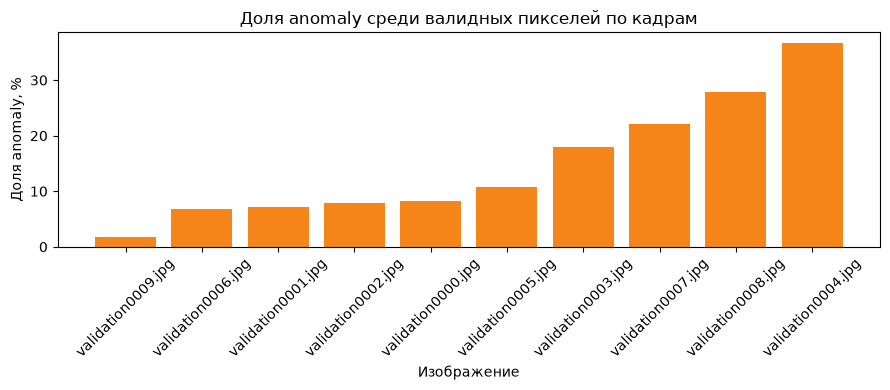

In [51]:


def anomaly_mask(arr):
    if arr.ndim == 2:
        if ANOMALY_VALUES is None:
            raise ValueError("Укажи проверенные значения anomaly в ANOMALY_VALUES")
        return np.isin(arr, list(ANOMALY_VALUES))

    if arr.ndim == 3:
        if ANOMALY_COLORS is None:
            raise ValueError("Для цветной маски укажи проверенные цвета в ANOMALY_COLORS")
        colors = np.asarray(list(ANOMALY_COLORS), dtype=arr.dtype)
        return np.any(
            np.all(arr[..., None, :] == colors[None, None, :, :], axis=-1),
            axis=-1,
        )

    raise ValueError(f"Неизвестная форма маски: {arr.shape}")


rows = []

for image_path, mask_path in pairs:
    with Image.open(mask_path) as mask:
        arr = np.asarray(mask)

    anomaly_pixels_mask = anomaly_mask(arr)

    if arr.ndim == 2 and VOID_VALUES is not None:
        valid_pixels_mask = ~np.isin(arr, list(VOID_VALUES))
    else:
        valid_pixels_mask = np.ones(anomaly_pixels_mask.shape, dtype=bool)

    valid_pixels = int(valid_pixels_mask.sum())
    anomaly_pixels = int((anomaly_pixels_mask & valid_pixels_mask).sum())
    anomaly_share = anomaly_pixels / valid_pixels if valid_pixels else np.nan

    rows.append({
        "image": image_path.name,
        "anomaly_pixels": anomaly_pixels,
        "valid_pixels": valid_pixels,
        "anomaly_share_valid": anomaly_share,
        "frame_anomaly_share_group": (
            "<0.5%" if anomaly_share < 0.005 else ">=0.5%"
        ) if valid_pixels else "нет валидных пикселей",
    })


area_df = pd.DataFrame(
    rows,
    columns=[
        "image",
        "anomaly_pixels",
        "valid_pixels",
        "anomaly_share_valid",
        "frame_anomaly_share_group",
    ],
).sort_values("anomaly_share_valid")

display(area_df)
display(
    area_df["frame_anomaly_share_group"]
    .value_counts()
    .rename_axis("group")
    .to_frame("image_count")
)

print("Граница 0,5% — описательная группировка доли anomaly на уровне кадра, не порог модели.")
print(
    "Средняя / медианная доля anomaly по кадрам: "
    f"{area_df['anomaly_share_valid'].mean():.2%} / "
    f"{area_df['anomaly_share_valid'].median():.2%}"
)
print(
    "Минимум / максимум доли anomaly по кадрам: "
    f"{area_df['anomaly_share_valid'].min():.2%} / "
    f"{area_df['anomaly_share_valid'].max():.2%}"
)

plot_area_df = area_df.sort_values("anomaly_share_valid")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    plot_area_df["image"],
    plot_area_df["anomaly_share_valid"] * 100,
    color="#F58518",
)
ax.set_title("Доля anomaly среди валидных пикселей по кадрам")
ax.set_ylabel("Доля anomaly, %")
ax.set_xlabel("Изображение")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 8. Размер связных anomaly-регионов

У масок нет отдельных instance ID, поэтому здесь считаются связные области пикселей со значением anomaly. Используется 8-связность: пиксели, соприкасающиеся по диагонали, входят в один регион. Это приближение для EDA, а не точное число физических объектов.

Срезы «меньше 0,1%» и «меньше 0,5%» относятся к площади одного региона относительно валидных пикселей кадра. Это описательные пороги, не официальный критерий размера объекта и не порог модели.


,image,connected_region_count,regions_lt_0_1pct,regions_lt_0_5pct
9,validation0009.jpg,7,0,7
0,validation0000.jpg,1,0,0
1,validation0001.jpg,1,0,0
2,validation0002.jpg,1,0,0
3,validation0003.jpg,1,0,0
4,validation0004.jpg,1,0,0
5,validation0005.jpg,1,0,0
6,validation0006.jpg,1,0,0
7,validation0007.jpg,1,0,0
8,validation0008.jpg,1,0,0


,area_share_valid_pct
count,16.000000
mean,9.223747
std,11.344553
min,0.128232
10%,0.173753
25%,0.241483
50%,7.008331
75%,12.611792
90%,25.026700
max,36.758315


,image,region_id,area_pixels,area_share_valid_pct
15,validation0009.jpg,7,1162,0.128232
13,validation0009.jpg,5,1378,0.152068
11,validation0009.jpg,3,1771,0.195438
12,validation0009.jpg,4,2135,0.235606
14,validation0009.jpg,6,2206,0.243442
10,validation0009.jpg,2,2491,0.274893
9,validation0009.jpg,1,4145,0.457419
6,validation0006.jpg,1,59574,6.776326
1,validation0001.jpg,1,65087,7.240336
2,validation0002.jpg,1,65974,7.936015


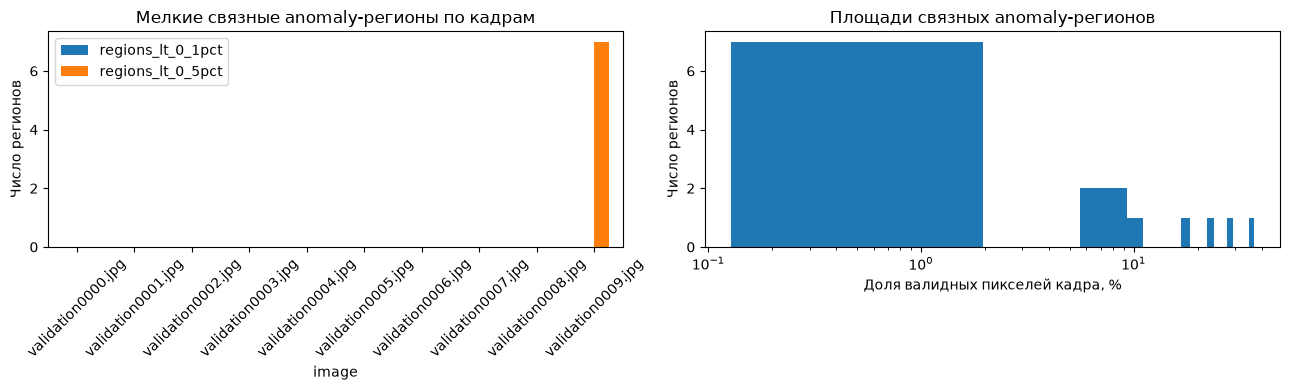

In [52]:
connectivity_8 = np.ones((3, 3), dtype=np.uint8)
component_rows = []
image_component_rows = []

for image_path, mask_path in pairs:
    with Image.open(mask_path) as mask:
        arr = np.asarray(mask)

    anomaly_pixels_mask = anomaly_mask(arr)

    if arr.ndim == 2 and VOID_VALUES is not None:
        valid_pixels_mask = ~np.isin(arr, list(VOID_VALUES))
    else:
        valid_pixels_mask = np.ones(anomaly_pixels_mask.shape, dtype=bool)

    regions, region_count = ndimage.label(
        anomaly_pixels_mask & valid_pixels_mask,
        structure=connectivity_8,
    )

    valid_pixels = int(valid_pixels_mask.sum())
    component_sizes = np.bincount(regions.ravel())[1:]
    component_shares = component_sizes / valid_pixels * 100

    for component_id, (pixel_count, share) in enumerate(
        zip(component_sizes, component_shares),
        start=1,
    ):
        component_rows.append({
            "image": image_path.name,
            "region_id": component_id,
            "area_pixels": int(pixel_count),
            "area_share_valid_pct": float(share),
        })

    image_component_rows.append({
        "image": image_path.name,
        "connected_region_count": int(region_count),
        "regions_lt_0_1pct": int((component_shares < 0.1).sum()),
        "regions_lt_0_5pct": int((component_shares < 0.5).sum()),
    })

component_df = pd.DataFrame(component_rows)
image_component_df = pd.DataFrame(image_component_rows)

display(
    image_component_df.sort_values(
        "regions_lt_0_5pct",
        ascending=False,
    )
)
display(
    component_df["area_share_valid_pct"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .to_frame("area_share_valid_pct")
)
display(
    component_df.nsmallest(20, "area_share_valid_pct")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

image_component_df.set_index("image")[
    ["regions_lt_0_1pct", "regions_lt_0_5pct"]
].plot(kind="bar", ax=axes[0])
axes[0].set_title("Мелкие связные anomaly-регионы по кадрам")
axes[0].set_ylabel("Число регионов")
axes[0].tick_params(axis="x", rotation=45)

axes[1].hist(component_df["area_share_valid_pct"], bins=20)
axes[1].set_xscale("log")
axes[1].set_title("Площади связных anomaly-регионов")
axes[1].set_xlabel("Доля валидных пикселей кадра, %")
axes[1].set_ylabel("Число регионов")

plt.tight_layout()
plt.show()


## 9. Визуальная проверка масок

В следующей ячейке показаны шесть выбранных пар изображения и маски; цвета маски обозначают not anomaly, anomaly и void.

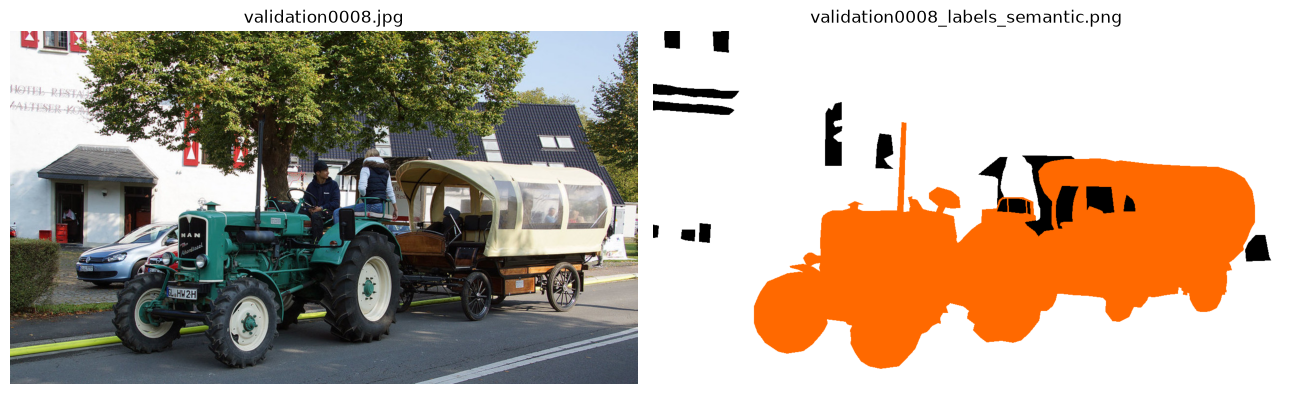

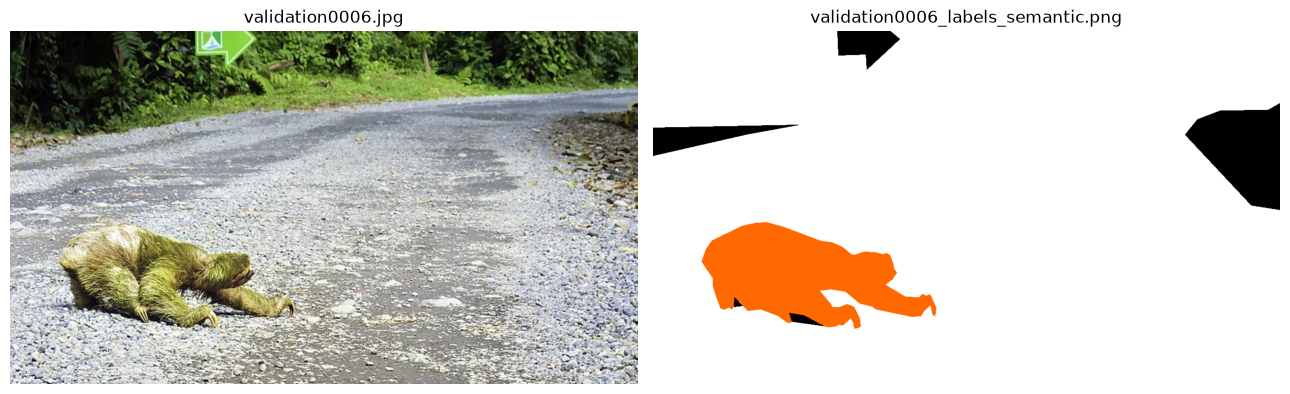

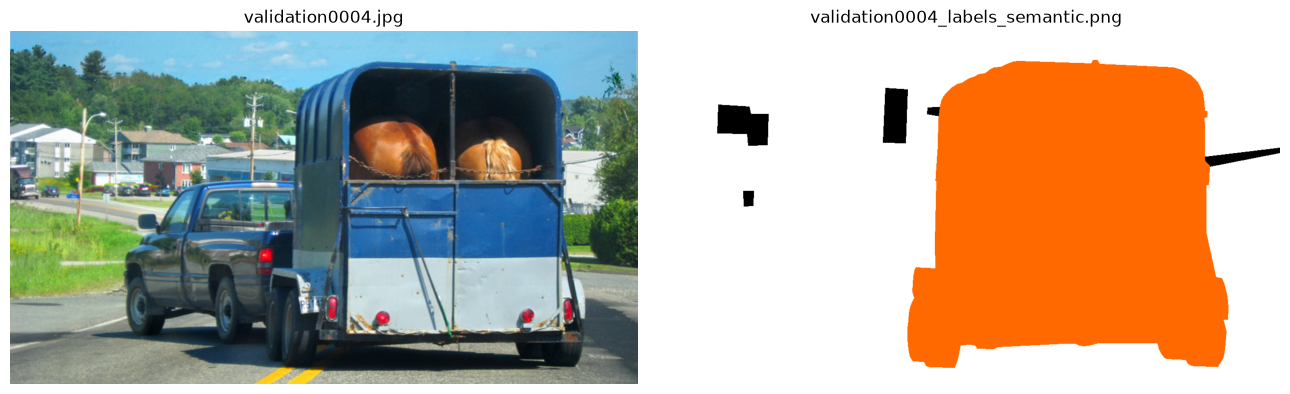

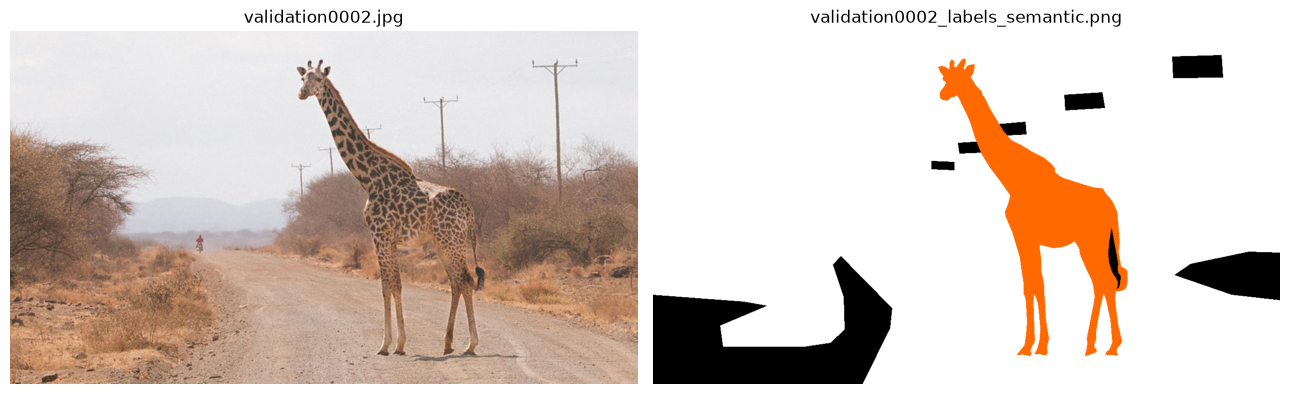

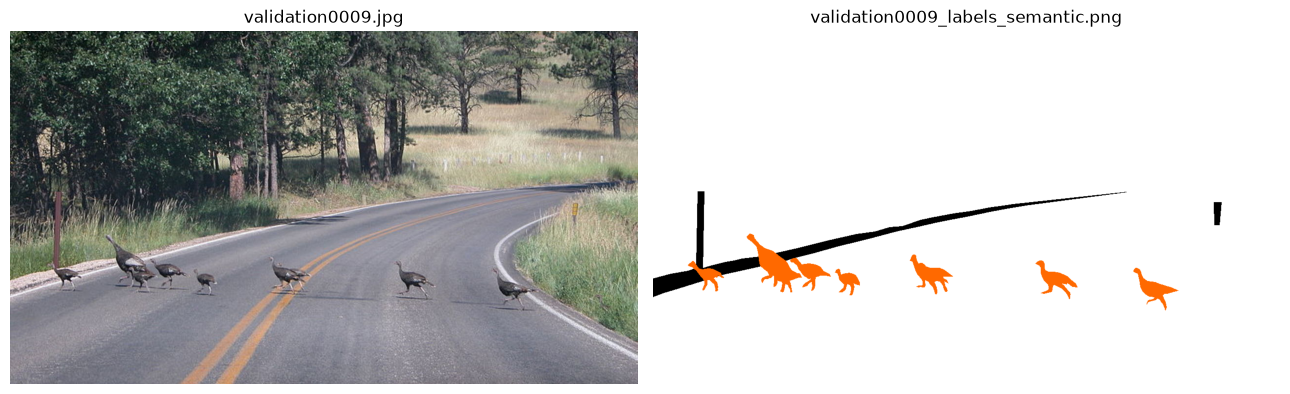

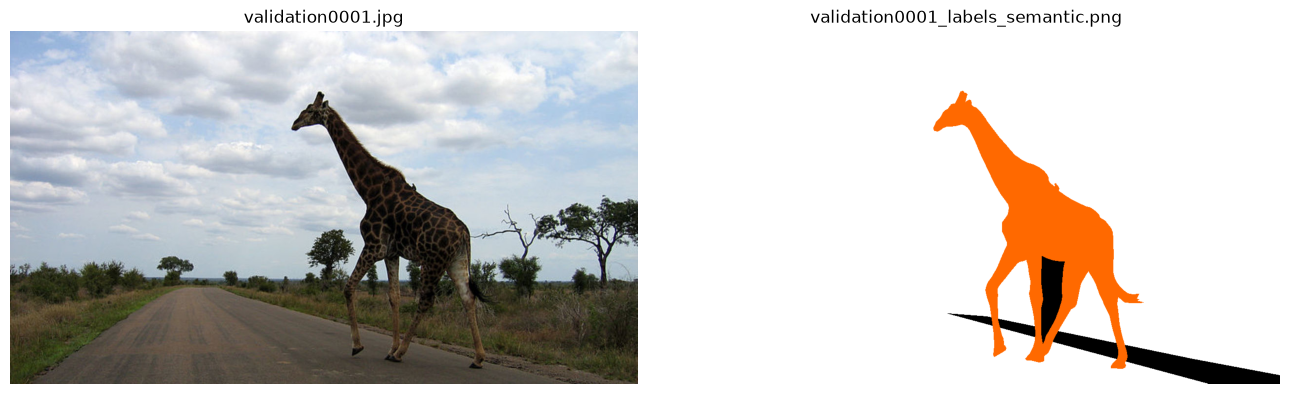

In [53]:

def show_pair(image_path, mask_path):
    with Image.open(image_path) as image:
        image_array = np.array(image.convert("RGB"))

    with Image.open(mask_path) as mask_image:
        mask = np.array(mask_image)

    if mask.ndim == 2:
        mask_display = np.zeros((*mask.shape, 3), dtype=np.uint8)
        mask_display[mask == 0] = (255, 255, 255)
        mask_display[mask == 1] = (255, 105, 0)
        mask_display[mask == 255] = (0, 0, 0)
    else:
        mask_display = mask

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].imshow(image_array)
    axes[0].set_title(image_path.name)
    axes[0].axis("off")

    axes[1].imshow(mask_display)
    axes[1].set_title(mask_path.name)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


sampled_pairs = random.Random(17).sample(
    pairs,
    k=min(6, len(pairs))
)

for image_path, mask_path in sampled_pairs:
    show_pair(image_path, mask_path)


## 10. Качественная проверка аугментаций

В этой секции показаны горизонтальное отражение, умеренное изменение яркости и контраста, а также лёгкое размытие. При отражении маска преобразуется вместе с изображением; цветовые преобразования и размытие применяются только к изображению. Для preview выбран кадр с самым маленьким связным регионом из рассчитанной таблицы.

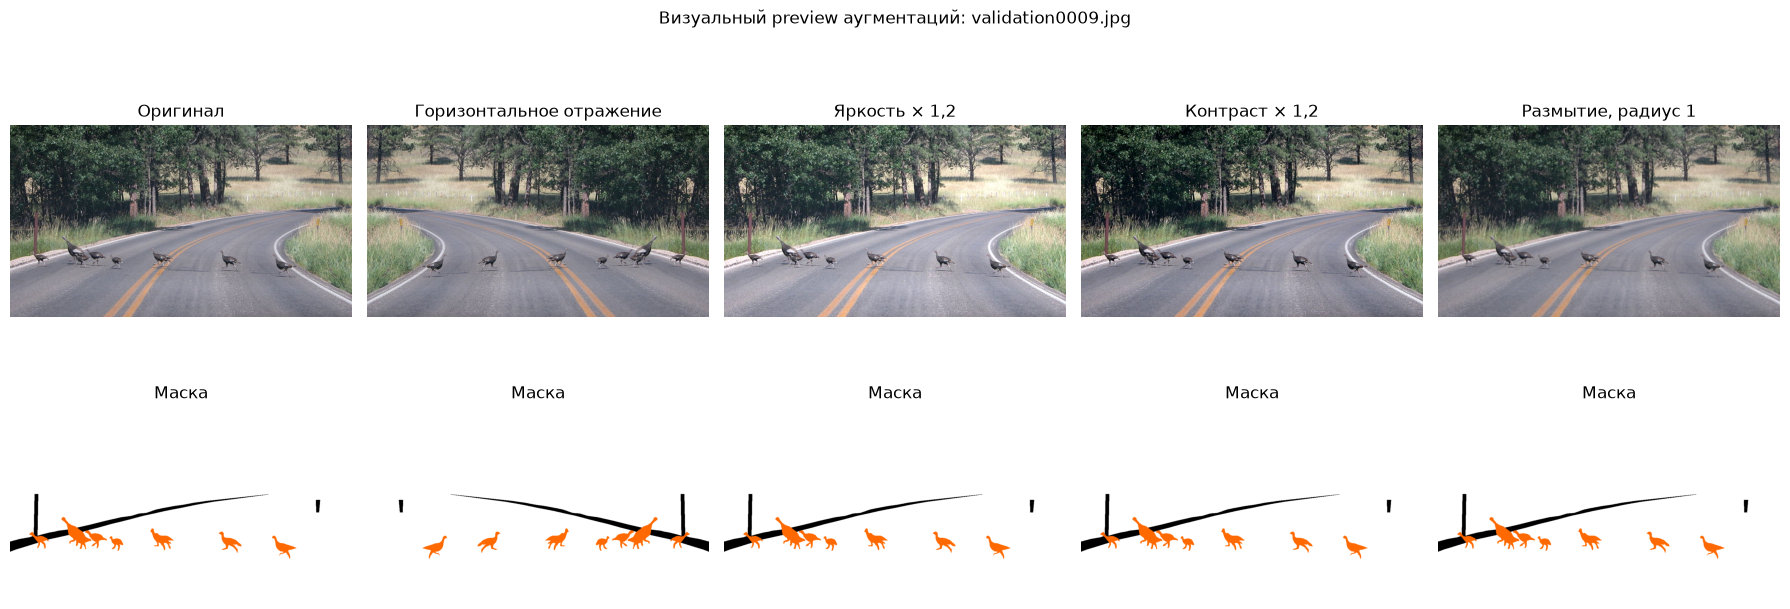

In [54]:
augmentation_image_name = (
    component_df.nsmallest(1, "area_share_valid_pct")
    .iloc[0]["image"]
)
augmentation_image_path, augmentation_mask_path = next(
    pair for pair in pairs if pair[0].name == augmentation_image_name
)

with Image.open(augmentation_image_path) as image_file:
    original_image = image_file.convert("RGB")
with Image.open(augmentation_mask_path) as mask_file:
    original_mask = mask_file.copy()

augmentation_variants = [
    (
        "Оригинал",
        original_image,
        original_mask,
    ),
    (
        "Горизонтальное отражение",
        ImageOps.mirror(original_image),
        ImageOps.mirror(original_mask),
    ),
    (
        "Яркость × 1,2",
        ImageEnhance.Brightness(original_image).enhance(1.2),
        original_mask,
    ),
    (
        "Контраст × 1,2",
        ImageEnhance.Contrast(original_image).enhance(1.2),
        original_mask,
    ),
    (
        "Размытие, радиус 1",
        original_image.filter(ImageFilter.GaussianBlur(radius=1)),
        original_mask,
    ),
]

def mask_to_rgb(mask_image):
    mask_array = np.asarray(mask_image)
    if mask_array.ndim == 2:
        mask_rgb = np.zeros((*mask_array.shape, 3), dtype=np.uint8)
        mask_rgb[mask_array == 0] = (255, 255, 255)
        mask_rgb[mask_array == 1] = (255, 105, 0)
        mask_rgb[mask_array == 255] = (0, 0, 0)
        return mask_rgb
    return mask_array.astype(np.uint8)

fig, axes = plt.subplots(2, len(augmentation_variants), figsize=(18, 7))

for column, (title, image_variant, mask_variant) in enumerate(augmentation_variants):
    axes[0, column].imshow(image_variant)
    axes[0, column].set_title(title)
    axes[0, column].axis("off")

    axes[1, column].imshow(mask_to_rgb(mask_variant))
    axes[1, column].set_title("Маска")
    axes[1, column].axis("off")

fig.suptitle(f"Визуальный preview аугментаций: {augmentation_image_name}")
plt.tight_layout()
plt.show()


### Оценка аугментаций

- **Горизонтальное отражение** сохраняет геометрию разметки при совместном преобразовании маски. Семантическая реалистичность зависит от дорожных знаков, надписей и асимметрии дорожного контекста.
- **Умеренные яркость и контраст** изменяют изображение без изменения маски и визуально соответствуют вариациям освещения.
- **Размытие** может скрыть небольшие и далёкие аномалии; на preview оно затрагивает детали малых регионов.

Это качественная визуальная оценка, а не измерение улучшения метрик. RoadAnomaly21 использован здесь как пример для preview; аугментации не применялись к benchmark test и не использовались для подбора порогов.

Визуально проверены 6 из 10 пар, выбранных с фиксированным seed 17. В просмотренных примерах области anomaly визуально соответствуют объектам на изображениях; явных ошибок сопоставления или грубого смещения не обнаружено. Белый цвет — not anomaly, оранжевый — anomaly, чёрный — void. Это проверка небольшого среза, она не подтверждает качество разметки всего набора.


## 11. Выводы по локальному RoadAnomaly21

### Наблюдения по данным

- В локальной опубликованной validation-части найдено 10 изображений и 10 исходных масок; пары сопоставились полностью. Несопоставленных файлов и несовпадений разрешений не обнаружено.
- Все изображения и маски имеют размер 1280×720. Изображения RGB, исходные маски одноканальные L.
- В масках присутствуют значения 0 (not anomaly), 1 (anomaly) и 255 (void). По всем пикселям набора доли составляют примерно 82,23%, 14,29% и 3,48% соответственно. При расчёте доли anomaly void исключён из знаменателя.
- Доля anomaly по кадрам лежит примерно между 1,69% и 36,76%; среднее около 14,76%, медиана около 9,57%. Все десять кадров превышают описательную границу 0,5%, используемую только для группировки.
- При визуальном просмотре шести пар не обнаружено явных ошибок сопоставления или грубого геометрического смещения. Этот результат относится только к просмотренному срезу.
- Связные регионы бинарной маски не являются точным числом экземпляров объектов; пороги 0,1% и 0,5% использованы для описания их размеров.

### Интерпретация для MSP и Energy

Площади anomaly-регионов заметно различаются. Поэтому агрегированная pixel-wise оценка может скрывать различия между крупными и малыми регионами; размер региона и ложные тревоги важны для интерпретации результатов MSP/Energy. Void занимает отдельную часть пикселей и исключён из расчётов. Локальные 10 изображений дают характеристику опубликованного среза, а не всего benchmark-набора.

## 13. EDA изображений Cityscapes: leftImg8bit_trainvaltest

В разделе собрана статистика RGB-изображений по split и городам, разрешению, режиму, читаемости и размеру файлов; яркость рассчитана на фиксированной выборке.

В каталоге leftImg8bit находятся изображения без семантических масок. Баланс 19 классов и характеристики разметки рассчитываются отдельно по соответствующим gtFine-аннотациям.

Папка Cityscapes: /Users/artur/Desktop/HomeWork/YearProj/leftImg8bit_trainvaltest
Папка изображений: /Users/artur/Desktop/HomeWork/YearProj/leftImg8bit_trainvaltest/leftImg8bit


,path,image_id,split,city,width,height,mode,format,file_size_mb,read_error
0,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,berlin_000000_000019,test,berlin,2048,1024,RGB,PNG,2.235318,None
1,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,berlin_000001_000019,test,berlin,2048,1024,RGB,PNG,2.355700,None
2,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,berlin_000002_000019,test,berlin,2048,1024,RGB,PNG,2.288315,None
3,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,berlin_000003_000019,test,berlin,2048,1024,RGB,PNG,2.083694,None
4,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,berlin_000004_000019,test,berlin,2048,1024,RGB,PNG,2.236352,None


,image_count,city_count,readable_count,reference_train_val,difference_from_reference
split,,,,,
test,1525,6,1525,NaN,NaN
train,2975,18,2975,2975.0,0.0
val,500,3,500,500.0,0.0


split,test,train,val
city,,,
aachen,0,174,0
berlin,544,0,0
bielefeld,181,0,0
bochum,0,96,0
bonn,46,0,0
bremen,0,316,0
cologne,0,154,0
darmstadt,0,85,0
dusseldorf,0,221,0


,width,height,image_count
0,2048,1024,5000


,mode,format,image_count
0,RGB,PNG,5000


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,1525.0,2.165822,0.143371,1.627656,2.072321,2.160235,2.251849,2.811090
train,2975.0,2.226722,0.176035,1.767430,2.103512,2.214864,2.336390,2.953040
val,500.0,2.253354,0.159766,1.583380,2.142442,2.244496,2.355886,2.680263


,path,image_id,split,city,width,height,mode,format,file_size_mb,read_error


Файлов с ошибкой чтения: 0


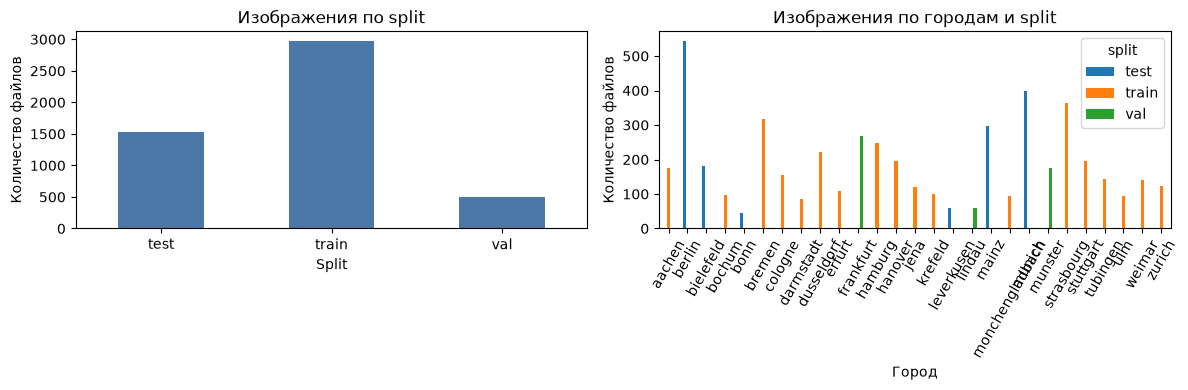

In [55]:
# Укажите здесь путь к папке leftImg8bit_trainvaltest.
# Путь задан явно, чтобы он не зависел от текущей рабочей папки ядра.
CITYSCAPES_ROOT = Path("/Users/artur/Desktop/HomeWork/YearProj/leftImg8bit_trainvaltest")
CITYSCAPES_IMAGE_ROOT = CITYSCAPES_ROOT / "leftImg8bit"

print("Папка Cityscapes:", CITYSCAPES_ROOT.resolve())
print("Папка изображений:", CITYSCAPES_IMAGE_ROOT.resolve())

cityscapes_paths = sorted(
    CITYSCAPES_IMAGE_ROOT.glob("*/*/*_leftImg8bit.png")
)
if not cityscapes_paths:
    raise FileNotFoundError(
        "Изображения не найдены. Проверьте CITYSCAPES_ROOT и структуру "
        "leftImg8bit/train|val|test/city/*.png."
    )

cityscapes_rows = []

for image_path in cityscapes_paths:
    split = image_path.parent.parent.name
    city = image_path.parent.name
    read_error = None
    width = height = None
    mode = image_format = None

    try:
        with Image.open(image_path) as image:
            image.load()
            width, height = image.size
            mode = image.mode
            image_format = image.format
    except Exception as error:
        read_error = f"{type(error).__name__}: {error}"

    cityscapes_rows.append({
        "path": str(image_path),
        "image_id": image_path.stem.removesuffix("_leftImg8bit"),
        "split": split,
        "city": city,
        "width": width,
        "height": height,
        "mode": mode,
        "format": image_format,
        "file_size_mb": image_path.stat().st_size / (1024 ** 2),
        "read_error": read_error,
    })

cityscapes_df = pd.DataFrame(cityscapes_rows)
display(cityscapes_df.head())

split_summary = (
    cityscapes_df.groupby("split")
    .agg(
        image_count=("path", "size"),
        city_count=("city", "nunique"),
        readable_count=("read_error", lambda values: values.isna().sum()),
    )
    .sort_index()
)
split_summary["reference_train_val"] = split_summary.index.map({
    "train": 2975,
    "val": 500,
})
split_summary["difference_from_reference"] = (
    split_summary["image_count"] - split_summary["reference_train_val"]
)
display(split_summary)

city_split_counts = cityscapes_df.pivot_table(
    index="city",
    columns="split",
    values="path",
    aggfunc="count",
    fill_value=0,
)
display(city_split_counts)

resolution_counts = (
    cityscapes_df.groupby(["width", "height"], dropna=False)
    .size()
    .rename("image_count")
    .reset_index()
)
display(resolution_counts)

display(
    cityscapes_df.groupby(["mode", "format"], dropna=False)
    .size()
    .rename("image_count")
    .reset_index()
)
display(
    cityscapes_df.groupby("split")["file_size_mb"]
    .describe()
)
display(cityscapes_df.loc[cityscapes_df["read_error"].notna()])
print(
    "Файлов с ошибкой чтения:",
    int(cityscapes_df["read_error"].notna().sum()),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_summary["image_count"].plot(
    kind="bar",
    ax=axes[0],
    color="#4C78A8",
)
axes[0].set_title("Изображения по split")
axes[0].set_xlabel("Split")
axes[0].set_ylabel("Количество файлов")
axes[0].tick_params(axis="x", rotation=0)

city_split_counts.plot(
    kind="bar",
    ax=axes[1],
)
axes[1].set_title("Изображения по городам и split")
axes[1].set_xlabel("Город")
axes[1].set_ylabel("Количество файлов")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()


### Яркость и визуальная проверка

Чтобы не декодировать все большие изображения для статистик пикселей, ниже берётся до 30 изображений на каждый split. Средняя яркость и стандартное отклонение яркости — только описательные признаки для поиска сильно отличающихся кадров, не метрики качества изображения.


mean_luminance                                                    \
               count      mean       std       min       25%       50%   
split                                                                    
test            30.0  0.303763  0.041332  0.216811  0.276606  0.304959   
train           30.0  0.293429  0.035875  0.236411  0.273134  0.283252   
val             30.0  0.323063  0.046708  0.216906  0.294616  0.341187   

                          std_luminance                                \
            75%       max         count      mean       std       min   
split                                                                   
test   0.328292  0.421242          30.0  0.181178  0.035626  0.112595   
train  0.310599  0.365449          30.0  0.184225  0.046141  0.107815   
val    0.353490  0.410780          30.0  0.187072  0.044911  0.118192   

                                               
            25%       50%       75%       max  
split                                          
test   0.163374  0.173430  0.204409  0.276352  
train  0.152007  0.177638  0.228546  0.260006  
val    0.159683  0.177826  0.209338  0.318707

,path,split,city,mean_luminance,std_luminance
24,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,test,berlin,0.216811,0.163980
62,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,munster,0.216906,0.180674
6,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,test,berlin,0.235278,0.130787
87,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,munster,0.235550,0.142789
52,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,train,dusseldorf,0.236411,0.176679


,path,split,city,mean_luminance,std_luminance
4,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,test,berlin,0.421242,0.222130
64,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,frankfurt,0.410780,0.198457
83,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,frankfurt,0.390247,0.205679
79,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,frankfurt,0.366792,0.212429
78,/Users/artur/Desktop/HomeWork/YearProj/leftImg...,val,frankfurt,0.365630,0.176796


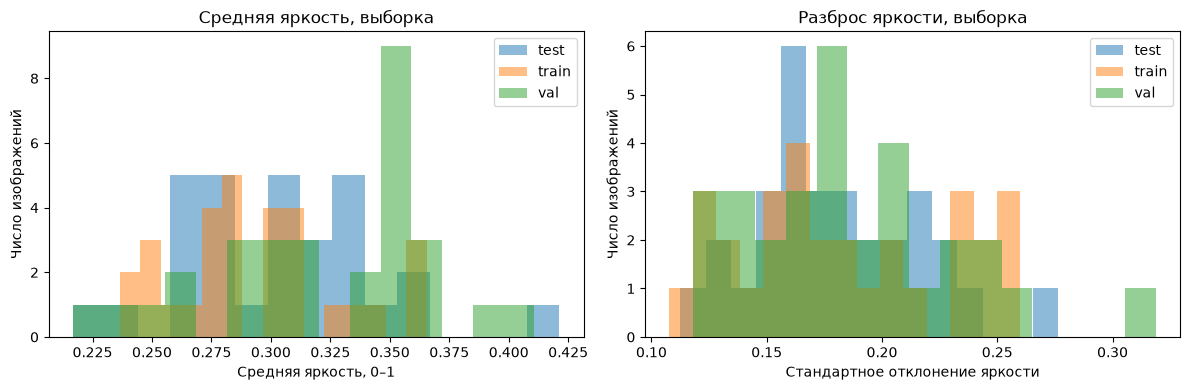

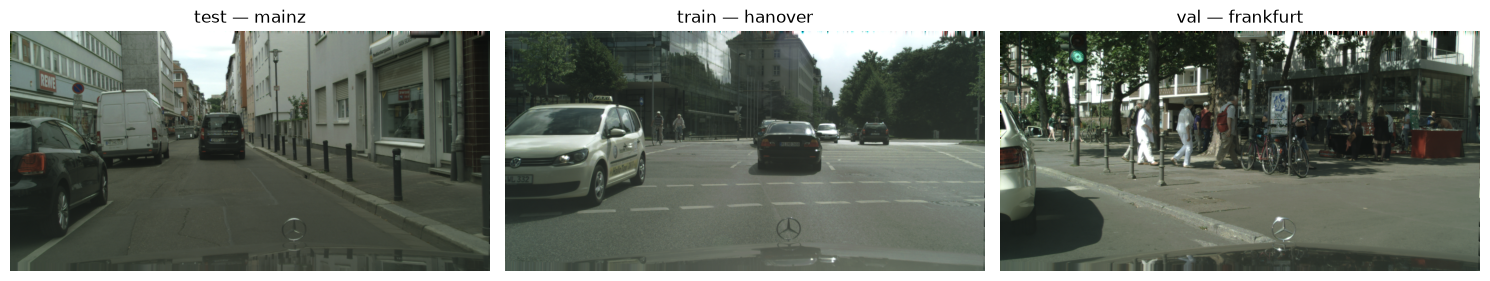

In [56]:
brightness_rows = []

for split, split_df in cityscapes_df.groupby("split"):
    readable_df = split_df.loc[split_df["read_error"].isna()]
    sampled_df = readable_df.sample(
        n=min(30, len(readable_df)),
        random_state=17,
    )

    for _, row in sampled_df.iterrows():
        with Image.open(row["path"]) as image:
            grayscale = np.asarray(image.convert("L"), dtype=np.float32) / 255.0

        brightness_rows.append({
            "path": row["path"],
            "split": split,
            "city": row["city"],
            "mean_luminance": float(grayscale.mean()),
            "std_luminance": float(grayscale.std()),
        })

cityscapes_brightness_df = pd.DataFrame(brightness_rows)

display(
    cityscapes_brightness_df.groupby("split")[
        ["mean_luminance", "std_luminance"]
    ].describe()
)
display(
    cityscapes_brightness_df.nsmallest(5, "mean_luminance")
)
display(
    cityscapes_brightness_df.nlargest(5, "mean_luminance")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, split_df in cityscapes_brightness_df.groupby("split"):
    axes[0].hist(
        split_df["mean_luminance"],
        bins=15,
        alpha=0.5,
        label=split,
    )
    axes[1].hist(
        split_df["std_luminance"],
        bins=15,
        alpha=0.5,
        label=split,
    )

axes[0].set_title("Средняя яркость, выборка")
axes[0].set_xlabel("Средняя яркость, 0–1")
axes[0].set_ylabel("Число изображений")
axes[0].legend()

axes[1].set_title("Разброс яркости, выборка")
axes[1].set_xlabel("Стандартное отклонение яркости")
axes[1].set_ylabel("Число изображений")
axes[1].legend()

plt.tight_layout()
plt.show()

preview_df = (
    cityscapes_df.loc[cityscapes_df["read_error"].isna()]
    .groupby("split", group_keys=False)
    .sample(n=1, random_state=17)
)

fig, axes = plt.subplots(
    1,
    len(preview_df),
    figsize=(5 * len(preview_df), 4),
    squeeze=False,
)

for ax, (_, row) in zip(axes[0], preview_df.iterrows()):
    with Image.open(row["path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row['split']} — {row['city']}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Выводы по изображениям Cityscapes

- В каталоге найдено 2 975 train, 500 val и 1 525 test изображений. Количества train и val совпадают с опубликованными размерами этих split.
- Все 5 000 файлов — читаемые RGB PNG размером 2048×1024; ошибок чтения не обнаружено.
- В фиксированной выборке по 30 кадров средняя яркость составила 0,293 для train, 0,323 для val и 0,304 для test. Значение для val выше в этой выборке; объём выборки не позволяет считать это доказательством систематического сдвига яркости между split.
- Семантические частоты классов не выводятся из RGB-изображений; они рассчитаны отдельно по gtFine labelIds.

## 14. EDA разметки Cityscapes: gtFine_trainvaltest

В разделе проверены пары изображений и gtFine-аннотаций, размеры масок и распределение 19 benchmark-классов по labelIds отдельно для train и val. Test учитывается в инвентаризации файлов, но не включается в расчёт баланса классов.

Корень gtFine задан как соседняя папка к leftImg8bit_trainvaltest.

In [57]:
CITYSCAPES_FINE_ROOT = (
    CITYSCAPES_ROOT.parent / "gtFine_trainvaltest" / "gtFine"
)
print("Папка gtFine:", CITYSCAPES_FINE_ROOT.resolve())

cityscapes_label_id_paths = sorted(
    CITYSCAPES_FINE_ROOT.glob("*/*/*_gtFine_labelIds.png")
)
cityscapes_instance_id_paths = sorted(
    CITYSCAPES_FINE_ROOT.glob("*/*/*_gtFine_instanceIds.png")
)
cityscapes_color_paths = sorted(
    CITYSCAPES_FINE_ROOT.glob("*/*/*_gtFine_color.png")
)
cityscapes_polygon_paths = sorted(
    CITYSCAPES_FINE_ROOT.glob("*/*/*_gtFine_polygons.json")
)

if not cityscapes_label_id_paths:
    raise FileNotFoundError(
        "Не найдены gtFine labelIds. Проверьте CITYSCAPES_ROOT и структуру "
        "gtFine/train|val|test/city/."
    )

annotation_inventory_rows = []
for split in ["train", "val", "test"]:
    annotation_inventory_rows.append({
        "split": split,
        "labelIds_png": len(list(CITYSCAPES_FINE_ROOT.glob(
            f"{split}/*/*_gtFine_labelIds.png"
        ))),
        "instanceIds_png": len(list(CITYSCAPES_FINE_ROOT.glob(
            f"{split}/*/*_gtFine_instanceIds.png"
        ))),
        "color_png": len(list(CITYSCAPES_FINE_ROOT.glob(
            f"{split}/*/*_gtFine_color.png"
        ))),
        "polygons_json": len(list(CITYSCAPES_FINE_ROOT.glob(
            f"{split}/*/*_gtFine_polygons.json"
        ))),
    })

annotation_inventory_df = pd.DataFrame(annotation_inventory_rows).set_index("split")
display(annotation_inventory_df)

def cityscapes_image_key(image_path):
    return (
        image_path.parent.parent.name,
        image_path.parent.name,
        image_path.stem.removesuffix("_leftImg8bit"),
    )

def cityscapes_label_key(label_path):
    return (
        label_path.parent.parent.name,
        label_path.parent.name,
        label_path.name.removesuffix("_gtFine_labelIds.png"),
    )

cityscapes_images_by_key = {
    cityscapes_image_key(image_path): image_path
    for image_path in cityscapes_paths
}
cityscapes_labels_by_key = {
    cityscapes_label_key(label_path): label_path
    for label_path in cityscapes_label_id_paths
}

cityscapes_image_keys = set(cityscapes_images_by_key)
cityscapes_label_keys = set(cityscapes_labels_by_key)
cityscapes_trainval_splits = {"train", "val"}

trainval_image_keys = {
    key for key in cityscapes_image_keys
    if key[0] in cityscapes_trainval_splits
}
trainval_label_keys = {
    key for key in cityscapes_label_keys
    if key[0] in cityscapes_trainval_splits
}
matched_trainval_keys = trainval_image_keys & trainval_label_keys
images_without_gtfine = sorted(trainval_image_keys - trainval_label_keys)
gtfine_without_images = sorted(trainval_label_keys - trainval_image_keys)

print(f"Изображений train/val: {len(trainval_image_keys)}")
print(f"Масок labelIds train/val: {len(trainval_label_keys)}")
print(f"Сопоставленных пар train/val: {len(matched_trainval_keys)}")
print(f"Изображений train/val без labelIds: {len(images_without_gtfine)}")
print(f"Масок train/val без изображения: {len(gtfine_without_images)}")

cityscapes_trainval_pairs = [
    {
        "key": key,
        "split": key[0],
        "city": key[1],
        "image_id": key[2],
        "image_path": cityscapes_images_by_key[key],
        "label_path": cityscapes_labels_by_key[key],
    }
    for key in sorted(matched_trainval_keys)
]


Папка gtFine: /Users/artur/Desktop/HomeWork/YearProj/gtFine_trainvaltest/gtFine


,labelIds_png,instanceIds_png,color_png,polygons_json
split,,,,
train,2975,2975,2975,2975
val,500,500,500,500
test,1525,1525,1525,1525


Изображений train/val: 3475
Масок labelIds train/val: 3475
Сопоставленных пар train/val: 3475
Изображений train/val без labelIds: 0
Масок train/val без изображения: 0


### Баланс классов по пикселям

Идентификаторы исходной маски преобразуются в trainId по официальному соответствию Cityscapes. Классы с trainId 255 считаются void/ignored и исключаются из знаменателя. Поэтому таблица показывает доли среди валидных пикселей отдельно для train и val, а также долю ignored-пикселей.


,split,class_name,train_id,pixel_count,share_valid_pixels_pct
0,train,road,0,2036416525,36.869696
1,train,sidewalk,1,336090793,6.084986
2,train,building,2,1260636120,22.824049
3,train,wall,3,36199498,0.655399
4,train,fence,4,48454166,0.877272
5,train,pole,5,67789506,1.227341
6,train,traffic light,6,11477088,0.207795
7,train,traffic sign,7,30448193,0.551270
8,train,vegetation,8,879783988,15.928651
9,train,terrain,9,63949536,1.157818


,split,valid_pixels,ignored_pixels,ignored_share_all_pixels_pct
0,train,5523279889,715747311,11.472098
1,val,917018489,131557511,12.546302


,split,class_name,mean_share_per_image_pct,median_share_per_image_pct,images_with_class,image_count
0,train,bicycle,0.428352,0.028042,1646,2975
1,train,building,23.062558,22.595031,2934,2975
2,train,bus,0.239906,0.000000,274,2975
3,train,car,6.990727,4.483907,2832,2975
4,train,fence,0.876278,0.000000,1296,2975
5,train,motorcycle,0.100145,0.000000,513,2975
6,train,person,1.259351,0.278597,2343,2975
7,train,pole,1.236591,0.966542,2949,2975
8,train,rider,0.137394,0.000000,1023,2975
9,train,road,36.693099,37.451454,2934,2975


,split,city,image_id,mask_mode,mask_size,image_size,sizes_match,raw_label_ids,unknown_raw_ids,ignored_share_all_pixels_pct
0,train,aachen,aachen_000000_000019,L,"(2048, 1024)","(2048, 1024)",True,"(0, 1, 3, 4, 7, 8, 11, 17, 20, 21, 22, 23, 24,...",(),6.095934
1,train,aachen,aachen_000001_000019,L,"(2048, 1024)","(2048, 1024)",True,"(0, 1, 3, 4, 5, 6, 7, 8, 11, 12, 13, 17, 19, 2...",(),7.813311
2,train,aachen,aachen_000002_000019,L,"(2048, 1024)","(2048, 1024)",True,"(0, 1, 3, 4, 5, 6, 7, 8, 11, 13, 17, 19, 20, 2...",(),6.318235
3,train,aachen,aachen_000003_000019,L,"(2048, 1024)","(2048, 1024)",True,"(0, 1, 3, 4, 7, 8, 11, 12, 17, 19, 20, 22, 23,...",(),5.599976
4,train,aachen,aachen_000004_000019,L,"(2048, 1024)","(2048, 1024)",True,"(0, 1, 3, 4, 6, 7, 8, 11, 13, 17, 19, 20, 21, ...",(),5.979204


Пар с несовпадающими размерами: 0
Неожиданные raw labelId: []


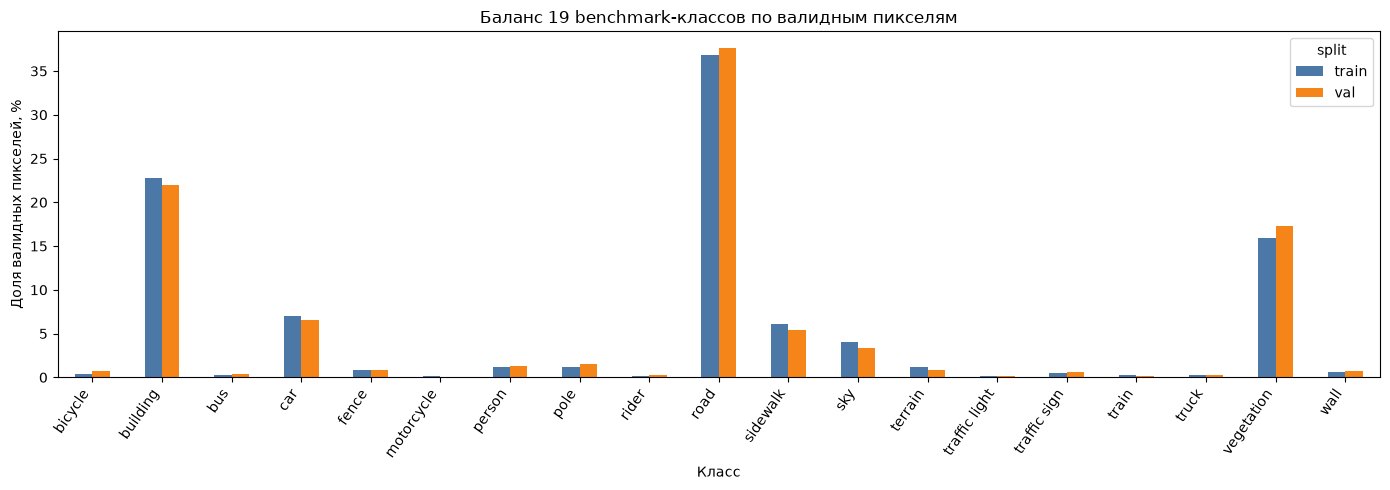

,split,raw_label_id,train_id,class_name,pixel_count
0,train,0,255,ignored / void,704950
1,train,1,255,ignored / void,286002726
2,train,2,255,ignored / void,81359604
3,train,3,255,ignored / void,94111150
4,train,4,255,ignored / void,83752079
...,...,...,...,...,...
62,val,29,255,ignored / void,53411
63,val,30,255,ignored / void,201086
64,val,31,16,train,1031648
65,val,32,17,motorcycle,729415


In [58]:
# Соответствие raw labelId -> benchmark trainId из официального labels.py.
# TrainId 255 означает ignored/void и не входит в 19 оцениваемых классов.
CITYSCAPES_TRAIN_ID_NAMES = {
    0: "road",
    1: "sidewalk",
    2: "building",
    3: "wall",
    4: "fence",
    5: "pole",
    6: "traffic light",
    7: "traffic sign",
    8: "vegetation",
    9: "terrain",
    10: "sky",
    11: "person",
    12: "rider",
    13: "car",
    14: "truck",
    15: "bus",
    16: "train",
    17: "motorcycle",
    18: "bicycle",
}

CITYSCAPES_RAW_TO_TRAIN_ID = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6,
    20: 7, 21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13,
    27: 14, 28: 15, 29: 255, 30: 255, 31: 16, 32: 17,
    33: 18, 255: 255,
}
CITYSCAPES_TRAIN_ID_LUT = np.full(256, 255, dtype=np.uint8)
for raw_id, train_id in CITYSCAPES_RAW_TO_TRAIN_ID.items():
    CITYSCAPES_TRAIN_ID_LUT[raw_id] = train_id

class_ids = sorted(CITYSCAPES_TRAIN_ID_NAMES)
class_counts_by_split = {
    split: np.zeros(len(class_ids), dtype=np.int64)
    for split in ["train", "val"]
}
valid_pixels_by_split = {"train": 0, "val": 0}
ignored_pixels_by_split = {"train": 0, "val": 0}
raw_id_counts_by_split = {
    split: {}
    for split in ["train", "val"]
}
per_image_class_rows = []
mask_quality_rows = []

for pair in cityscapes_trainval_pairs:
    split = pair["split"]

    with Image.open(pair["label_path"]) as label_image:
        label_image.load()
        label_mask = np.asarray(label_image)
        label_mode = label_image.mode
        label_size = label_image.size

    if label_mask.ndim != 2 or label_mask.dtype.kind not in "ui":
        raise ValueError(
            f"Ожидалась одноканальная целочисленная labelIds маска: "
            f"{pair['label_path'].name}; mode={label_mode}, shape={label_mask.shape}"
        )
    if label_mask.min() < 0 or label_mask.max() > 255:
        raise ValueError(
            f"Ожидались 8-битные labelIds со значениями 0..255: "
            f"{pair['label_path'].name}"
        )

    with Image.open(pair["image_path"]) as image:
        image.load()
        image_size = image.size

    raw_values, raw_counts = np.unique(label_mask, return_counts=True)
    raw_hist = raw_id_counts_by_split[split]
    for raw_id, pixel_count in zip(raw_values, raw_counts):
        raw_id = int(raw_id)
        raw_hist[raw_id] = raw_hist.get(raw_id, 0) + int(pixel_count)

    unknown_raw_ids = sorted(
        int(raw_id)
        for raw_id in raw_values
        if int(raw_id) not in CITYSCAPES_RAW_TO_TRAIN_ID
    )

    mapped_mask = CITYSCAPES_TRAIN_ID_LUT[label_mask.astype(np.uint8, copy=False)]
    valid_mask = mapped_mask < 19
    class_counts = np.bincount(
        mapped_mask[valid_mask],
        minlength=19,
    )
    valid_pixels = int(class_counts.sum())
    total_pixels = int(label_mask.size)
    ignored_pixels = total_pixels - valid_pixels

    class_counts_by_split[split] += class_counts
    valid_pixels_by_split[split] += valid_pixels
    ignored_pixels_by_split[split] += ignored_pixels

    for train_id in class_ids:
        pixel_count = int(class_counts[train_id])
        per_image_class_rows.append({
            "split": split,
            "city": pair["city"],
            "image_id": pair["image_id"],
            "class_name": CITYSCAPES_TRAIN_ID_NAMES[train_id],
            "class_pixels": pixel_count,
            "share_valid_pixels_pct": (
                pixel_count / valid_pixels * 100 if valid_pixels else np.nan
            ),
        })

    mask_quality_rows.append({
        "split": split,
        "city": pair["city"],
        "image_id": pair["image_id"],
        "mask_mode": label_mode,
        "mask_size": label_size,
        "image_size": image_size,
        "sizes_match": label_size == image_size,
        "raw_label_ids": tuple(int(value) for value in raw_values),
        "unknown_raw_ids": tuple(unknown_raw_ids),
        "ignored_share_all_pixels_pct": ignored_pixels / total_pixels * 100,
    })

class_balance_rows = []
ignored_balance_rows = []
for split in ["train", "val"]:
    valid_pixels = valid_pixels_by_split[split]
    for train_id in class_ids:
        class_balance_rows.append({
            "split": split,
            "class_name": CITYSCAPES_TRAIN_ID_NAMES[train_id],
            "train_id": train_id,
            "pixel_count": int(class_counts_by_split[split][train_id]),
            "share_valid_pixels_pct": (
                class_counts_by_split[split][train_id] / valid_pixels * 100
                if valid_pixels else np.nan
            ),
        })

    total_pixels = valid_pixels + ignored_pixels_by_split[split]
    ignored_balance_rows.append({
        "split": split,
        "valid_pixels": valid_pixels,
        "ignored_pixels": ignored_pixels_by_split[split],
        "ignored_share_all_pixels_pct": (
            ignored_pixels_by_split[split] / total_pixels * 100
            if total_pixels else np.nan
        ),
    })

cityscapes_class_balance_df = pd.DataFrame(class_balance_rows)
cityscapes_ignored_balance_df = pd.DataFrame(ignored_balance_rows)
cityscapes_per_image_class_df = pd.DataFrame(per_image_class_rows)
cityscapes_mask_quality_df = pd.DataFrame(mask_quality_rows)

display(cityscapes_class_balance_df)
display(cityscapes_ignored_balance_df)
display(
    cityscapes_per_image_class_df.groupby(["split", "class_name"])
    .agg(
        mean_share_per_image_pct=("share_valid_pixels_pct", "mean"),
        median_share_per_image_pct=("share_valid_pixels_pct", "median"),
        images_with_class=("class_pixels", lambda values: (values > 0).sum()),
        image_count=("class_pixels", "size"),
    )
    .reset_index()
)
display(cityscapes_mask_quality_df.head())
print(
    "Пар с несовпадающими размерами:",
    int((~cityscapes_mask_quality_df["sizes_match"]).sum()),
)
print(
    "Неожиданные raw labelId:",
    sorted({
        raw_id
        for values in cityscapes_mask_quality_df["unknown_raw_ids"]
        for raw_id in values
    }),
)

class_balance_plot_df = cityscapes_class_balance_df.pivot(
    index="class_name",
    columns="split",
    values="share_valid_pixels_pct",
)
class_balance_plot_df.plot(
    kind="bar",
    figsize=(14, 5),
    color={"train": "#4C78A8", "val": "#F58518"},
)
plt.title("Баланс 19 benchmark-классов по валидным пикселям")
plt.ylabel("Доля валидных пикселей, %")
plt.xlabel("Класс")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

raw_label_rows = []
for split in ["train", "val"]:
    for raw_id, pixel_count in sorted(raw_id_counts_by_split[split].items()):
        train_id = CITYSCAPES_RAW_TO_TRAIN_ID.get(raw_id, 255)
        raw_label_rows.append({
            "split": split,
            "raw_label_id": raw_id,
            "train_id": train_id,
            "class_name": CITYSCAPES_TRAIN_ID_NAMES.get(
                train_id,
                "ignored / void",
            ),
            "pixel_count": pixel_count,
        })

cityscapes_raw_id_balance_df = pd.DataFrame(raw_label_rows)
display(cityscapes_raw_id_balance_df)


### Примеры image–mask

Ниже показано по одной выбранной паре для train и val. Цветные маски предназначены для визуального просмотра; численные расчёты выполнены по labelIds.

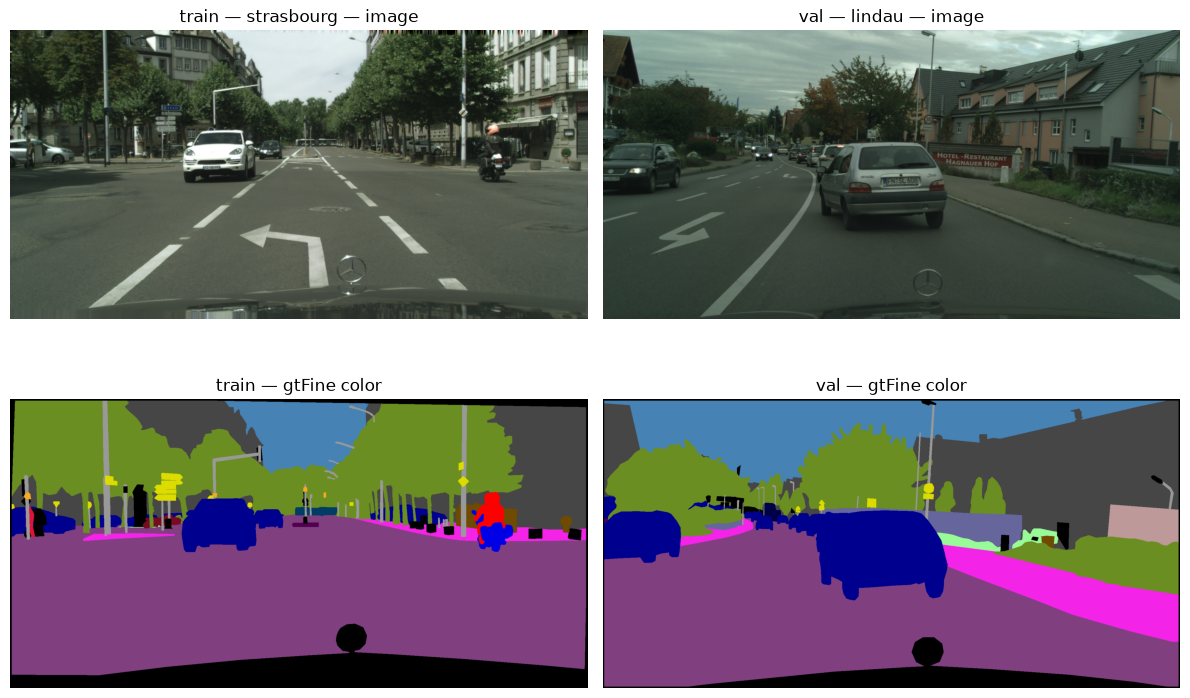

In [59]:
cityscapes_color_by_key = {
    (
        color_path.parent.parent.name,
        color_path.parent.name,
        color_path.name.removesuffix("_gtFine_color.png"),
    ): color_path
    for color_path in cityscapes_color_paths
}

preview_keys = []
for split in ["train", "val"]:
    split_keys = [
        pair["key"]
        for pair in cityscapes_trainval_pairs
        if pair["split"] == split
        and pair["key"] in cityscapes_color_by_key
    ]
    preview_keys.append(random.Random(17).choice(split_keys))

fig, axes = plt.subplots(2, len(preview_keys), figsize=(12, 8))

for column, key in enumerate(preview_keys):
    image_path = cityscapes_images_by_key[key]
    label_path = cityscapes_labels_by_key[key]
    color_path = cityscapes_color_by_key[key]

    with Image.open(image_path) as image:
        image_array = np.asarray(image.convert("RGB"))
    with Image.open(color_path) as color_mask:
        color_mask_array = np.asarray(color_mask.convert("RGB"))

    axes[0, column].imshow(image_array)
    axes[0, column].set_title(f"{key[0]} — {key[1]} — image")
    axes[0, column].axis("off")

    axes[1, column].imshow(color_mask_array)
    axes[1, column].set_title(f"{key[0]} — gtFine color")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()


### Выводы по gtFine

- В train и val сопоставлены все 3 475 изображений с масками: 2 975 пар в train и 500 в val. У всех проверенных пар совпадают размеры; неожиданных raw labelId не найдено. Это подтверждает целостность проверенной разметки для этих двух частей.
- Распределение классов по валидным пикселям выраженно неравномерное. В train доли road, building и vegetation составляют 36,87%, 22,82% и 15,93%; в val — 37,65%, 21,92% и 17,32%. Доля car — около 7% в обеих частях.
- Motorcycle занимает 0,10% валидных пикселей train и 0,08% val; rider — 0,14% и 0,22%. Общая pixel accuracy в такой ситуации сильнее отражает крупные классы, чем редкие.
- Общая картина train и val похожа: в обеих частях преобладают road, building и vegetation. В val доля vegetation выше примерно на 1,40 процентного пункта, а road — на 0,78 пункта. Эти различия сами по себе не указывают на ошибку разбиения.
- Игнорируемые пиксели составляют 11,47% всех пикселей train и 12,55% val; в таблицах долей классов они исключены из валидного знаменателя.
- В фиксированной выборке по 30 изображений средняя яркость составила 0,293 для train и 0,323 для val. Это описательное различие в небольшой выборке, а не свидетельство систематического сдвига между частями набора.

В контексте проекта Cityscapes характеризует известные классы семантического сегментатора, а RoadAnomaly21 — неизвестные объекты. Распределение классов Cityscapes задаёт контекст для интерпретации выходов MSP и Energy на распространённых и редких классах.

В этом анализе class balance считается только по train и val. Test используется как отложенная benchmark-оценка; полноценные аннотации для официального тестирования скрыты. Сопоставление и численный баланс построены по labelIds; instanceIds и polygons относятся к задачам экземпляров и геометрии разметки.

Источники соответствия labelId/trainId: официальный [Cityscapes labels.py](https://github.com/mcordts/cityscapesScripts/blob/master/cityscapesscripts/helpers/labels.py) и [README скриптов Cityscapes](https://github.com/mcordts/cityscapesScripts).